# TP2 - Análisis de un PDF con Python

**Documento elegido:** *Odisea demográfica. Tendencias demográficas en Argentina*

Este notebook descarga el PDF, inspecciona sus metadatos, analiza la estructura del texto, extrae una tabla y realiza un análisis básico de frecuencias.

## 1. Descarga e importación de librerías

In [ ]:
!pip -q install pdfplumber pypdf nltk

import io
import re
import requests
import pdfplumber
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from pypdf import PdfReader

PDF_URL = 'https://www.unicef.org/argentina/media/16156/file/Odisea%20demogr%C3%A1fica.%20Tendencias%20demogr%C3%A1ficas%20en%20Argentina%3A%20insumos%20claves%20para%20el%20dise%C3%B1o%20del%20bienestar%20social..pdf'
PDF_PATH = 'PDF_TP2.pdf'

respuesta = requests.get(PDF_URL, timeout=60)
respuesta.raise_for_status()
with open(PDF_PATH, 'wb') as archivo:
    archivo.write(respuesta.content)

print(f'Archivo descargado: {PDF_PATH}')
print(f'Tamaño: {len(respuesta.content) / 1024:.1f} KB')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 825.1 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 1.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 22.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 395.5/395.5 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 24.3 MB/s eta 0:00:00
Archivo descargado: PDF_TP2.pdf
Tamaño: 1435.4 KB


## 2. Adquisición y metadatos

In [ ]:
reader = PdfReader(PDF_PATH)
metadata = reader.metadata

titulo = metadata.get('/Title') or 'Odisea demográfica: Tendencias demográficas en Argentina'
print('Título:', titulo)
print('Autor:', metadata.get('/Author', 'No informado'))
print('Cantidad de páginas:', len(reader.pages))
print('Software de creación:', metadata.get('/Creator', 'No informado'))
print('Productor:', metadata.get('/Producer', 'No informado'))

Título: Odisea demográfica: Tendencias demográficas en Argentina
Autor: Carola della Paolera
Cantidad de páginas: 41
Software de creación: Microsoft® Word 2013
Productor: Microsoft® Word 2013


## 3. Análisis estructural del texto



In [ ]:
with pdfplumber.open(PDF_PATH) as pdf:
    pagina_texto = pdf.pages[2]
    texto_crudo = pagina_texto.extract_text(x_tolerance=2, y_tolerance=3) or ''

print(texto_crudo[:4000])

PROGRAMA DE PROTECCIÓN SOCIAL INFORME
Resumen
En los últimos 30 años, aún en períodos de crecimiento económico, Argentina no ha
logrado reducir la incidencia de la pobreza por debajo del 25%. En otras palabras,
durante las últimas tres décadas, siempre hubo al menos un cuarto de la población que
vivió en la pobreza. La pobreza implica vulneraciones en múltiples dimensiones
(ingresos, educación, vivienda, etc.) y una política efectiva enfocada en este desafío
demanda la adopción de medidas en diversos campos, como la macroeconomía, los
mercados de trabajo, la educación, el cuidado y otras políticas sociales.
Habitualmente, en Argentina, estos temas son debatidos con un foco marcado en
encontrar soluciones de corto plazo a los problemas, lo que dificulta cristalizar mejoras
significativas y sostenibles. A esto se suma el hecho de que es habitual que una
dimensión tan relevante como las anteriores sea ignorada: la dinámica demográfica.
La evolución de la población, en tamaño y estructura 

In [ ]:
print('Representación cruda de los primeros caracteres:')
print(repr(texto_crudo[:1000]))

print('Cantidad de caracteres:', len(texto_crudo))
print('Saltos de línea \n:', texto_crudo.count('\n'))
print('Retornos de carro \r:', texto_crudo.count('\r'))
print('Tabulaciones \t:', texto_crudo.count('\t'))
print('Secuencias de dos o más espacios:', len(re.findall(r' {2,}', texto_crudo)))
print('Párrafos aproximados:', len([p for p in texto_crudo.split('\n\n') if p.strip()]))

Representación cruda de los primeros caracteres:
'PROGRAMA DE PROTECCIÓN SOCIAL INFORME\nResumen\nEn los últimos 30 años, aún en períodos de crecimiento económico, Argentina no ha\nlogrado reducir la incidencia de la pobreza por debajo del 25%. En otras palabras,\ndurante las últimas tres décadas, siempre hubo al menos un cuarto de la población que\nvivió en la pobreza. La pobreza implica vulneraciones en múltiples dimensiones\n(ingresos, educación, vivienda, etc.) y una política efectiva enfocada en este desafío\ndemanda la adopción de medidas en diversos campos, como la macroeconomía, los\nmercados de trabajo, la educación, el cuidado y otras políticas sociales.\nHabitualmente, en Argentina, estos temas son debatidos con un foco marcado en\nencontrar soluciones de corto plazo a los problemas, lo que dificulta cristalizar mejoras\nsignificativas y sostenibles. A esto se suma el hecho de que es habitual que una\ndimensión tan relevante como las anteriores sea ignorada: la dinámica demo

## 4. Extracción de datos tabulares

La tabla seleccionada se encuentra en la página física 16 y presenta la tasa de fecundidad adolescente por región.

In [ ]:
with pdfplumber.open(PDF_PATH) as pdf:
    pagina_tabla = pdf.pages[15]
    tablas = pagina_tabla.extract_tables()

print('Cantidad de tablas detectadas:', len(tablas))
for i, tabla in enumerate(tablas, start=1):
    celdas = sum(bool(celda and str(celda).strip()) for fila in tabla for celda in fila)
    print(f'Tabla {i}: {len(tabla)} filas, {max(map(len, tabla))} columnas, {celdas} celdas con contenido')

tabla_mayor = max(tablas, key=lambda tabla: sum(bool(celda and str(celda).strip()) for fila in tabla for celda in fila))
display(pd.DataFrame(tabla_mayor))

Cantidad de tablas detectadas: 3
Tabla 1: 2 filas, 1 columnas, 1 celdas con contenido
Tabla 2: 6 filas, 3 columnas, 4 celdas con contenido
Tabla 3: 22 filas, 12 columnas, 28 celdas con contenido


,0,1,2,3,4,5,6,7,8,9,10,11
0,None,None,None,,None,None,,None,None,,None,None
1,None,None,None,,Tasa de fecundidad,,Cambios entre 2014 y 2017,None,None,Cambios entre 2018 y 2020,None,None
2,None,None,None,None,adolescente en 2020,None,None,None,None,None,None,None
3,None,None,None,,None,None,,None,None,,None,None
4,,None,None,,None,None,,None,None,,None,None
5,Total país,None,None,"15,2",None,None,-20%,None,None,-39%,None,None
6,,None,None,,None,None,,None,None,,None,None
7,,None,None,,None,None,,None,None,,None,None
8,,Patagonia,,,"12,1",,,-29%,,,-37%,
9,,None,None,,None,None,,None,None,,None,None


In [ ]:
# Limpieza programática de la tabla extraída. Se eliminan filas vacías y se normalizan los nombres.
regiones = ['Total país', 'Patagonia', 'Pampeana', 'Cuyo', 'NOA', 'NEA']
filas_limpias = []

for fila in tabla_mayor:
    celdas = [str(celda).strip() if celda else '' for celda in fila]
    texto_fila = ' '.join(celdas).replace('�', 'í')
    region = next((r for r in regiones if r in texto_fila), None)
    valores = [c for c in celdas if re.fullmatch(r'-?\d+(?:[,.]\d+)?%?', c)]
    if region and len(valores) >= 3:
        region = region.replace('Pampeana', 'Pampeana')
        tasa = float(valores[0].replace(',', '.'))
        cambio_1 = float(valores[1].replace('%', '').replace(',', '.'))
        cambio_2 = float(valores[2].replace('%', '').replace(',', '.'))
        filas_limpias.append([region, tasa, cambio_1, cambio_2])

df_tabla = pd.DataFrame(filas_limpias, columns=[
    'Región',
    'Tasa de fecundidad adolescente en 2020',
    'Cambio entre 2014 y 2017 (%)',
    'Cambio entre 2018 y 2020 (%)'
])
df_tabla

,Región,Tasa de fecundidad adolescente en 2020,Cambio entre 2014 y 2017 (%),Cambio entre 2018 y 2020 (%)
0,Total país,15.2,-20.0,-39.0
1,Patagonia,12.1,-29.0,-37.0
2,Pampeana,13.1,-19.0,-39.0
3,Cuyo,15.3,-30.0,-37.0
4,NOA,18.1,-16.0,-43.0
5,NEA,28.2,-11.0,-34.0


## 5. Análisis básico de frecuencias


In [ ]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

stopwords_es = set(stopwords.words('spanish'))
tokens = re.findall(r'\b[^\W\d_]+\b', texto_crudo.lower(), flags=re.UNICODE)
tokens_limpios = [t for t in tokens if t not in stopwords_es and len(t) > 1 and '�' not in t]
frecuencias = Counter(tokens_limpios)
top15 = frecuencias.most_common(15)

print('Cantidad de tokens originales:', len(tokens))
print('Cantidad de tokens luego de la limpieza:', len(tokens_limpios))
top15

Cantidad de tokens originales: 614
Cantidad de tokens luego de la limpieza: 314


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


[('fecundidad', 9),
 ('argentina', 7),
 ('pobreza', 6),
 ('tendencia', 6),
 ('dónde', 4),
 ('sociales', 3),
 ('cambios', 3),
 ('niveles', 3),
 ('países', 3),
 ('territorios', 3),
 ('descenso', 3),
 ('social', 2),
 ('aún', 2),
 ('económico', 2),
 ('reducir', 2)]

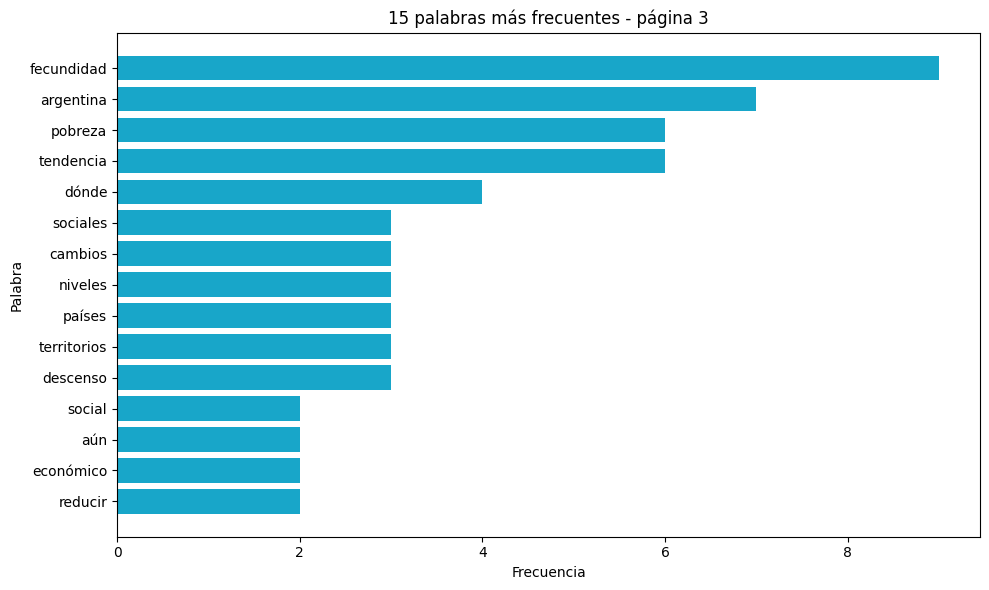

In [ ]:
palabras = [x[0] for x in top15][::-1]
valores = [x[1] for x in top15][::-1]

plt.figure(figsize=(10, 6))
plt.barh(palabras, valores, color='#18a6c9')
plt.title('15 palabras más frecuentes - página 3')
plt.xlabel('Frecuencia')
plt.ylabel('Palabra')
plt.tight_layout()
plt.show()

### Conclusiones

Las palabras más frecuentes deberían relacionarse con los ejes principales del resumen: población, fecundidad, pobreza, Argentina y demografía. Algunas palabras que sobrevivan a la eliminación automática podrían funcionar como stopwords específicas del documento, por ejemplo términos muy generales o institucionales. Esto debe revisarse mirando el gráfico y justificando cada decisión.

La extracción también muestra que no todos los PDFs conservan perfectamente la codificación de caracteres. En este documento, los caracteres acentuados aparecen dañados en algunas extracciones, aunque visualmente se ven correctamente.